# Lab 4 · Online machine learning on data streams

Adam Chgour · M2 Data Science · Institut Polytechnique de Paris

This notebook reads the archived experimental outcomes. See the [PDF report](output/pdf/lab-4-online-machine-learning.pdf) for interpretation and the [README](README.md) for datasets, model settings and reproduction instructions. Run `./reproduce.sh` in the repository root to replay the experiments and rebuild this notebook.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

def read(name):
    return pd.read_csv(Path('results') / f'{name}.csv')

def plot(name):
    display(Image(filename=f'figures/{name}.png', width=800))

pd.options.display.float_format = '{:,.4f}'.format
read('environment')

,item,value
0,CPU,Apple M2
1,RAM,16 GB
2,Python,3.12.7
3,Platform,Darwin 26.5.2 arm64
4,Java,"openjdk version ""17.0.14"" 2025-01-21"
5,river,0.23.0
6,capymoa,0.15.0
7,numpy,2.5.5
8,pandas,2.3.3
9,scikit-learn,1.9.1


## River regression

All four learners predict each row before updating. MAE and RMSE are in the target’s units. The panels show mean predict-plus-train latency versus MAE on each stream.

,stream,model,n,mae,rmse,r2,wall_s,mean_us,p95_us
0,SeoulBikes,HT,8759,252.3206,404.3162,0.6070,0.8965,101.9660,32.2584
1,SeoulBikes,ARF,8759,179.7772,275.9935,0.8169,2.7592,314.4085,"1,166.5952"
2,SeoulBikes,AdaGrad,8759,171.0044,268.6178,0.8265,0.0773,8.4862,8.7090
3,SeoulBikes,kNN,8759,169.4131,265.9492,0.8300,4.4977,512.7593,552.5461
4,ApplianceEnergy,HT,19734,33.3120,70.7513,0.5238,1.2840,64.6870,36.5420
5,ApplianceEnergy,ARF,19734,34.9611,74.7829,0.4680,6.0109,303.9530,919.7398
6,ApplianceEnergy,AdaGrad,19734,33.1490,68.4233,0.5546,0.1594,7.7434,7.9580
7,ApplianceEnergy,kNN,19734,35.0730,75.5767,0.4566,9.5619,483.8082,518.4580
8,MetroTraffic,HT,12000,763.4051,"1,141.6815",0.6774,0.8088,67.0015,23.1670
9,MetroTraffic,ARF,12000,420.2000,604.6913,0.9095,2.8050,233.1591,715.2982


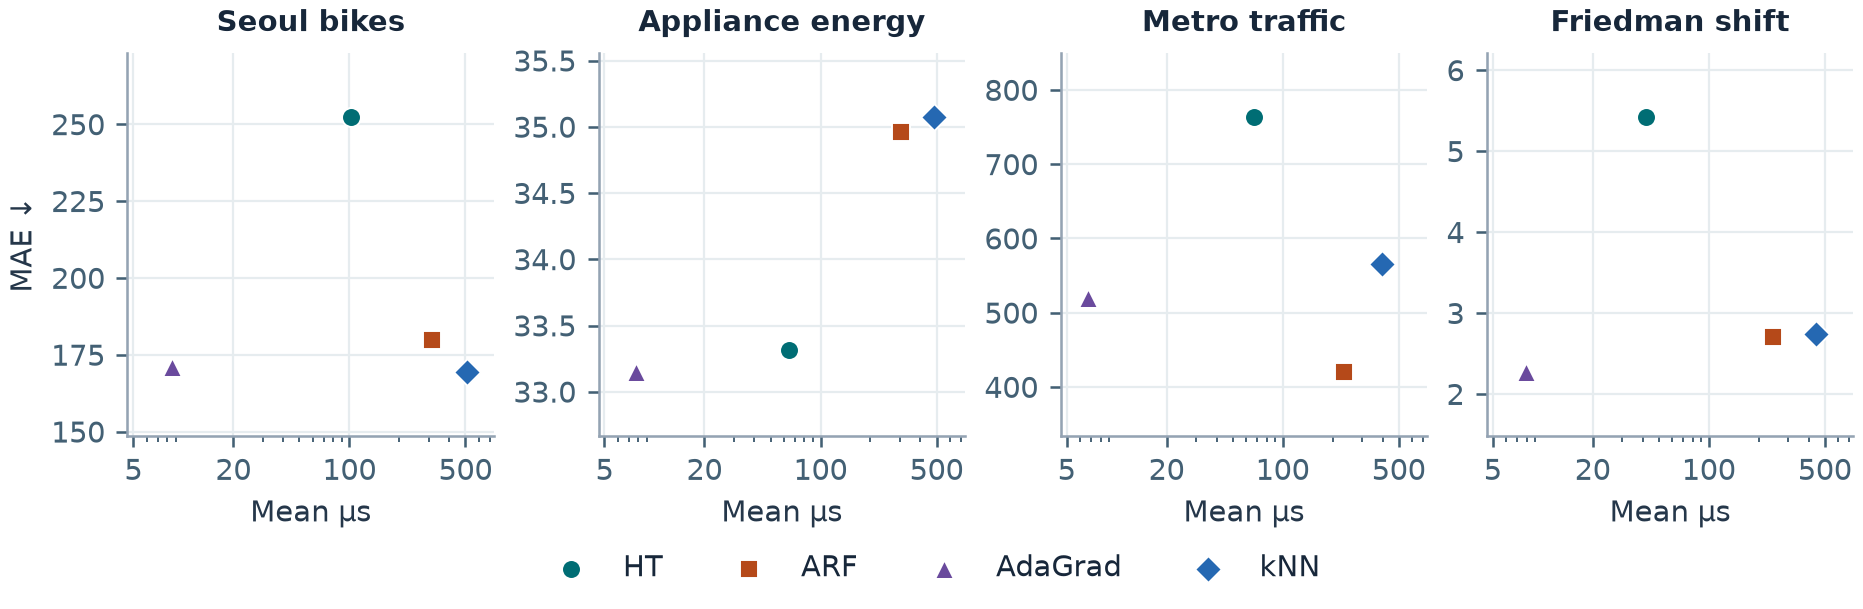

In [2]:
reg = read('river_regression')
display(reg[['stream', 'model', 'n', 'mae', 'rmse', 'r2', 'wall_s', 'mean_us', 'p95_us']])
plot('regression')

## River regression drift

Detector inputs are clipped absolute errors scaled using the first 100 targets. Monitor-only preserves the baseline learner. Reset replaces it after scoring an alarm row. The synthetic shift starts at row 5,001.

,stream,detector,policy,alarms,pre_change_alarms,delay,first_1000_after,score,mean_us
0,SeoulBikes,NaN,baseline,0,NaN,NaN,NaN,252.3206,101.9660
1,SeoulBikes,ADWIN,monitor,9,NaN,NaN,NaN,252.3206,103.9891
2,SeoulBikes,ADWIN,reset,10,NaN,NaN,NaN,270.9771,86.8493
3,SeoulBikes,PageHinkley,monitor,5,NaN,NaN,NaN,252.3206,103.1338
4,SeoulBikes,PageHinkley,reset,2,NaN,NaN,NaN,202.4628,89.3378
5,SeoulBikes,KSWIN,monitor,36,NaN,NaN,NaN,252.3206,230.7997
6,SeoulBikes,KSWIN,reset,44,NaN,NaN,NaN,354.9689,185.6953
7,ApplianceEnergy,NaN,baseline,0,NaN,NaN,NaN,33.3120,64.6870
8,ApplianceEnergy,ADWIN,monitor,7,NaN,NaN,NaN,33.3120,66.7469
9,ApplianceEnergy,ADWIN,reset,18,NaN,NaN,NaN,43.2322,62.3848


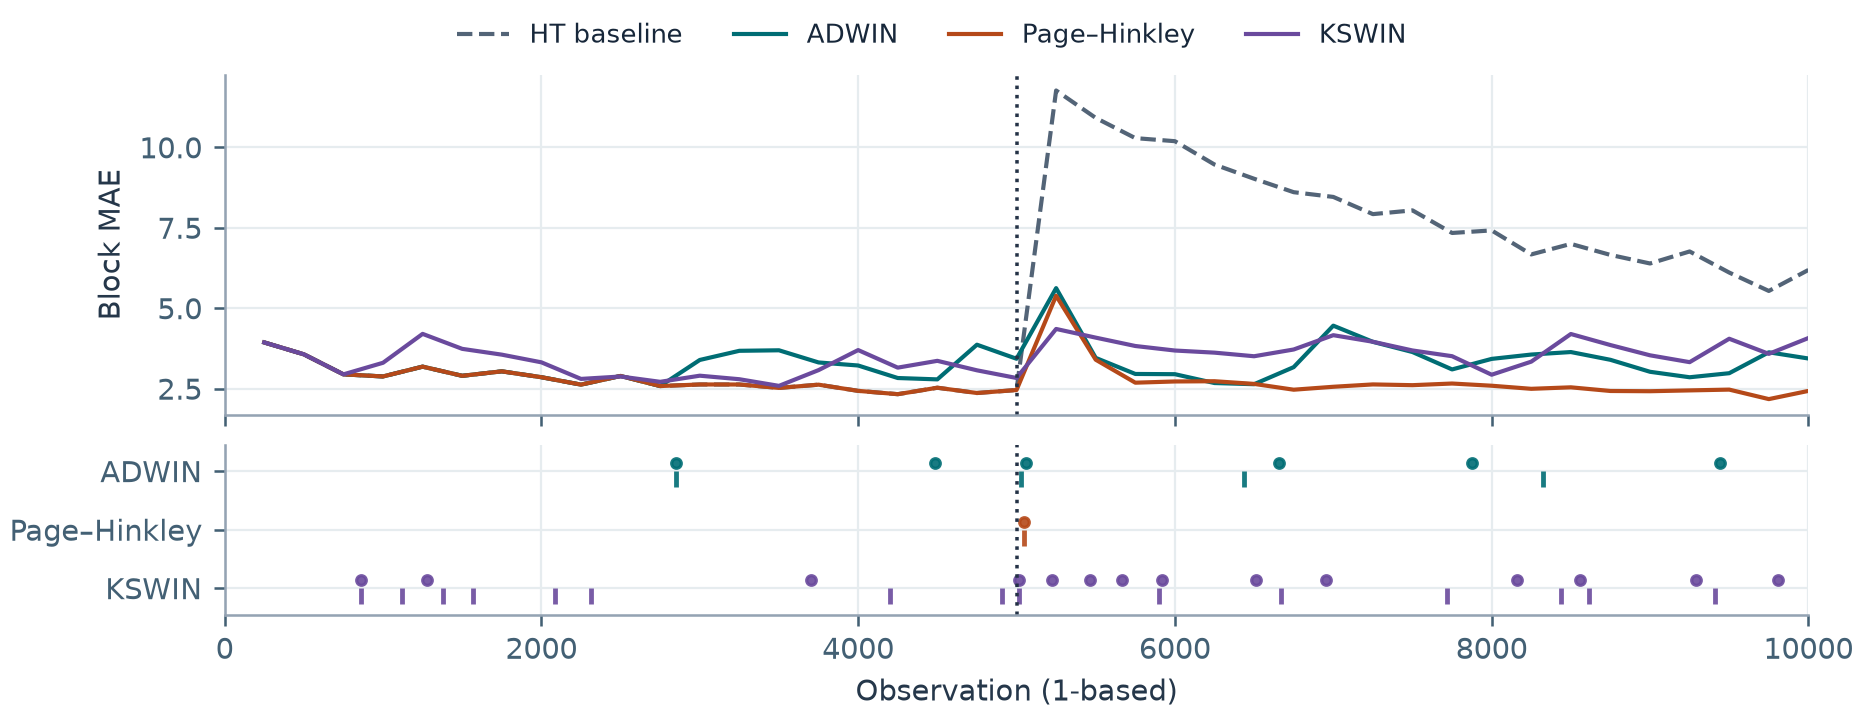

In [3]:
display(read('regression_drift').drop(columns=['n', 'wall_s', 'p95_us']))
plot('regression_drift')

## River classification

Macro F1 weighs both classes equally. Kappa adjusts accuracy for expected agreement based on the predicted and observed class frequencies.

,stream,model,n,accuracy,macro_f1,kappa,wall_s,mean_us,p95_us
0,Occupancy,HT,20560,0.9807,0.9736,0.9471,0.1546,7.2407,6.8330
1,Occupancy,ARF,20560,0.9768,0.9676,0.9352,1.6585,80.2824,142.3770
2,Occupancy,Logistic,20560,0.9668,0.9530,0.9061,0.1076,4.9444,5.0830
3,Occupancy,GaussianNB,20560,0.9614,0.9479,0.8960,0.8108,39.0961,42.3340
4,EEGEyeState,HT,14980,0.5852,0.5844,0.1717,0.2388,15.6377,13.2920
5,EEGEyeState,ARF,14980,0.9678,0.9675,0.9349,1.0730,71.2753,107.7931
6,EEGEyeState,Logistic,14980,0.9048,0.9037,0.8074,0.1339,8.6548,9.2920
7,EEGEyeState,GaussianNB,14980,0.4741,0.3809,0.0350,0.7551,50.0464,58.6670
8,GasSensorDrift,HT,5574,0.5531,0.5038,0.0652,0.0810,14.2442,11.4170
9,GasSensorDrift,ARF,5574,0.8066,0.8040,0.6084,0.7431,132.8401,299.6817


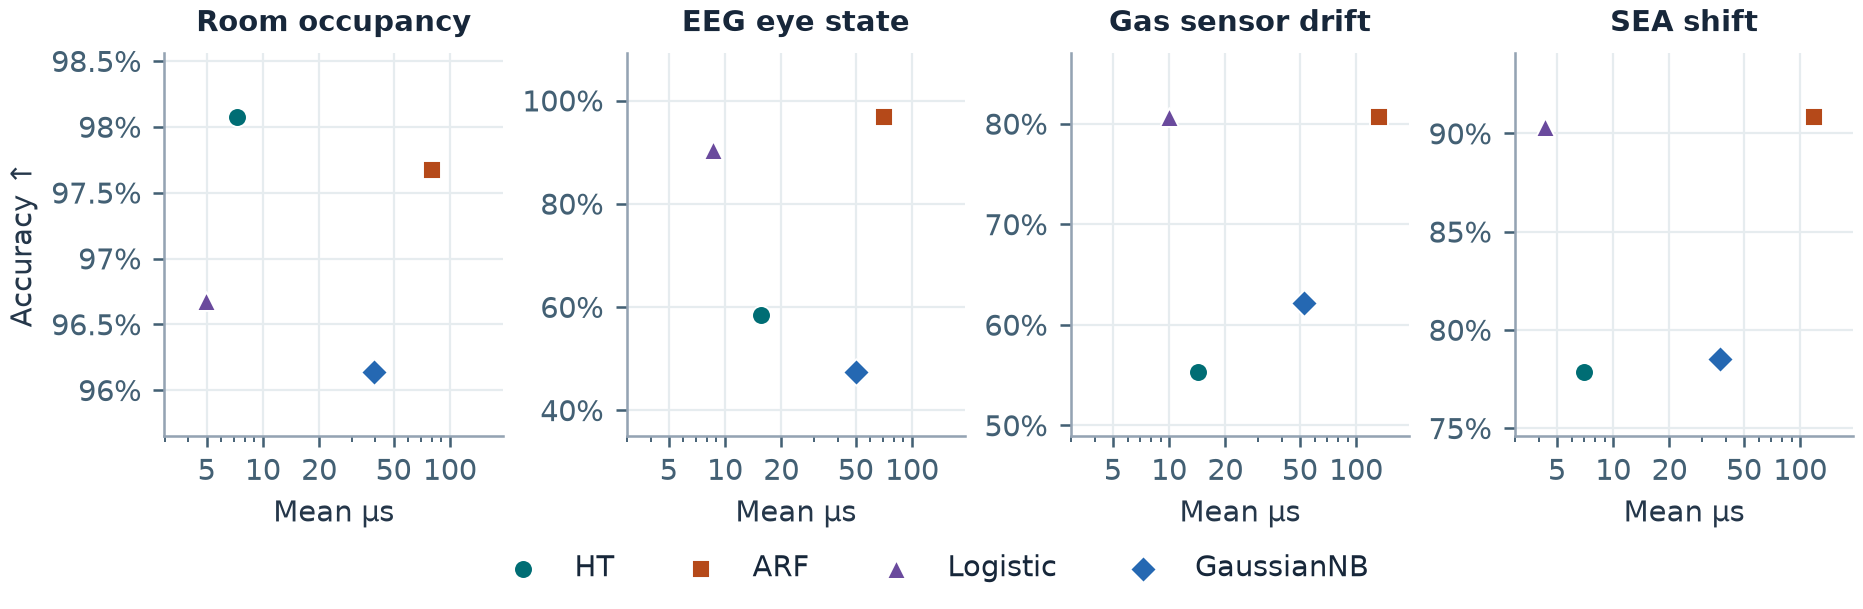

In [4]:
clf = read('river_classification')
display(clf[['stream', 'model', 'n', 'accuracy', 'macro_f1', 'kappa', 'wall_s', 'mean_us', 'p95_us']])
plot('classification')

## River classification drift

The detectors receive 0/1 prediction errors. SEA shifts at row 5,001. The alarm logs also include the real-stream results. All positions are 1-based.

,stream,detector,policy,alarms,pre_change_alarms,delay,first_1000_after,score,mean_us
0,Occupancy,NaN,baseline,0,NaN,NaN,NaN,0.9807,7.2407
1,Occupancy,ADWIN,monitor,6,NaN,NaN,NaN,0.9807,9.1545
2,Occupancy,ADWIN,reset,30,NaN,NaN,NaN,0.9559,7.1751
3,Occupancy,DDM,monitor,2,NaN,NaN,NaN,0.9807,7.5798
4,Occupancy,DDM,reset,35,NaN,NaN,NaN,0.9828,5.8852
5,Occupancy,EDDM,monitor,5,NaN,NaN,NaN,0.9807,7.3874
6,Occupancy,EDDM,reset,21,NaN,NaN,NaN,0.9664,5.8539
7,Occupancy,HDDM_A,monitor,13,NaN,NaN,NaN,0.9807,18.2487
8,Occupancy,HDDM_A,reset,45,NaN,NaN,NaN,0.9853,17.2428
9,EEGEyeState,NaN,baseline,0,NaN,NaN,NaN,0.5852,15.6377


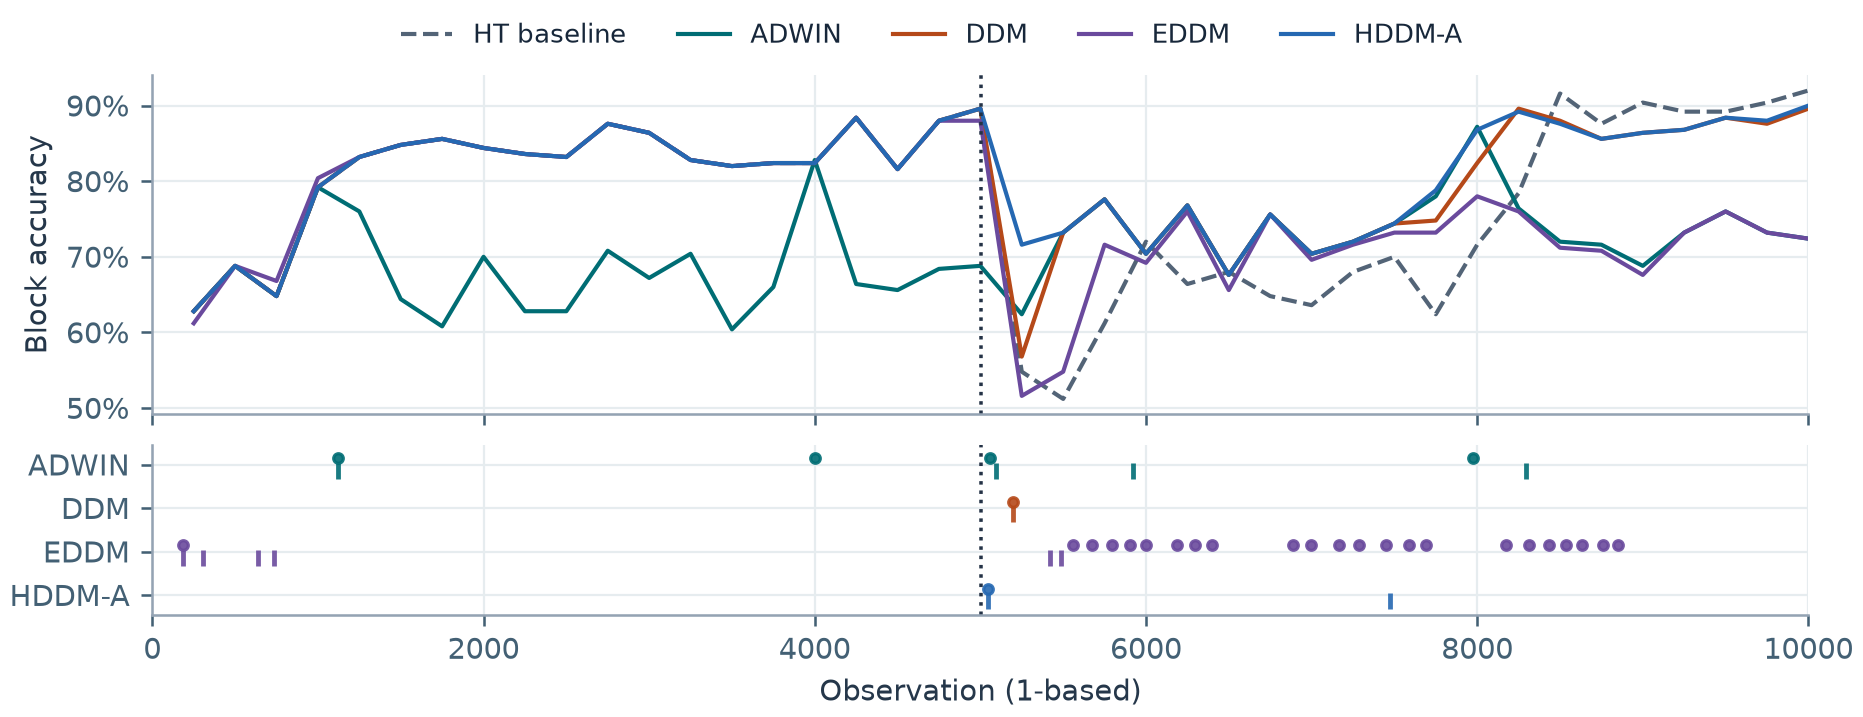

In [5]:
display(read('classification_drift').drop(columns=['n', 'wall_s', 'p95_us']))
plot('classification_drift')

In [6]:
for task in ('regression', 'classification'):
    alarms = read(f'{task}_alarms')
    display(alarms.groupby(['stream', 'detector', 'policy']).position.agg(['count', 'min', 'max']))

count   min    max
stream          detector    policy                     
ApplianceEnergy ADWIN       monitor      7  2148  18852
                            reset       18  2148  19204
                KSWIN       monitor    172   219  19628
                            reset      181   219  19676
                PageHinkley monitor      1  9366   9366
                            reset        1  9366   9366
FriedmanShift   ADWIN       monitor      4  2852   8324
                            reset        6  2852   9444
                KSWIN       monitor     15   864   9412
                            reset       14   864   9808
                PageHinkley monitor      1  5044   5044
                            reset        1  5044   5044
MetroTraffic    ADWIN       monitor      2  2084   4708
                            reset        4  2084   8836
                KSWIN       monitor     20   253  11643
                            reset       75   253  11984
SeoulBikes      ADWIN       monitor      9  1252   7428
                            reset       10  1252   8260
                KSWIN       monitor     36   393   8251
                            reset       44   393   8440
                PageHinkley monitor      5  2360   4248
                            reset        2  2360   4197

count   min    max
stream         detector policy                     
EEGEyeState    ADWIN    monitor     51   228  14884
                        reset       22   228  14980
               DDM      monitor     27   189  14733
                        reset       23   189  14960
               EDDM     monitor     57   219  14757
                        reset       19   219  14320
               HDDM_A   monitor     39   192  14715
                        reset       23   192  14963
GasSensorDrift ADWIN    monitor      5   644   4420
                        reset        5   644   4484
               DDM      monitor      3   188   4554
                        reset        4   188   4826
               EDDM     monitor      5   169   5150
                        reset       22   169   4665
               HDDM_A   monitor      4   199   4399
                        reset        4   199   4489
Occupancy      ADWIN    monitor      6   228  13636
                        reset       30   228  19684
               DDM      monitor      2   196   3861
                        reset       35   196  20552
               EDDM     monitor      5   234  16363
                        reset       21   234  19112
               HDDM_A   monitor     13   199  17651
                        reset       45   199  20555
SEAShift       ADWIN    monitor      4  1124   8292
                        reset        4  1124   7972
               DDM      monitor      1  5195   5195
                        reset        1  5195   5195
               EDDM     monitor      6   183   5488
                        reset       23   183   8852
               HDDM_A   monitor      2  5048   7472
                        reset        1  5048   5048

## River versus CapyMOA

Compare each learner pair on identical observations. River uses AdaGrad logistic regression while the CapyMOA counterpart uses inverse-scaling SGD with log loss.

,stream,model,accuracy_river,wall_s_river,mean_us_river,p95_us_river,rss_peak_mib_river,accuracy_capymoa,wall_s_capymoa,mean_us_capymoa,p95_us_capymoa,rss_peak_mib_capymoa
0,Occupancy,HT,0.9807,0.1546,7.2407,6.8330,185.5938,0.9805,0.4387,20.9937,23.4580,277.0625
1,Occupancy,ARF,0.9768,1.6585,80.2824,142.3770,186.3594,0.9636,0.6648,31.9838,33.9580,350.5938
2,Occupancy,Logistic,0.9668,0.1076,4.9444,5.0830,186.4531,0.9344,6.3944,310.3881,334.3750,357.2812
3,Occupancy,GaussianNB,0.9614,0.8108,39.0961,42.3340,186.4688,0.9604,0.3141,14.9650,15.3750,359.3906
4,EEGEyeState,HT,0.5852,0.2388,15.6377,13.2920,206.8125,0.5640,0.2727,17.8975,20.2500,376.7812
5,EEGEyeState,ARF,0.9678,1.0730,71.2753,107.7931,207.0156,0.9627,0.4561,30.1287,31.2080,377.0156
6,EEGEyeState,Logistic,0.9048,0.1339,8.6548,9.2920,207.0156,0.5649,4.6519,309.9089,336.4190,377.0469
7,EEGEyeState,GaussianNB,0.4741,0.7551,50.0464,58.6670,207.0312,0.4742,0.2350,15.3848,16.0410,377.0625
8,GasSensorDrift,HT,0.5531,0.0810,14.2442,11.4170,196.0625,0.5531,0.0898,15.7920,15.8340,364.5781
9,GasSensorDrift,ARF,0.8066,0.7431,132.8401,299.6817,196.0781,0.8249,0.2042,36.2977,114.7227,364.6562


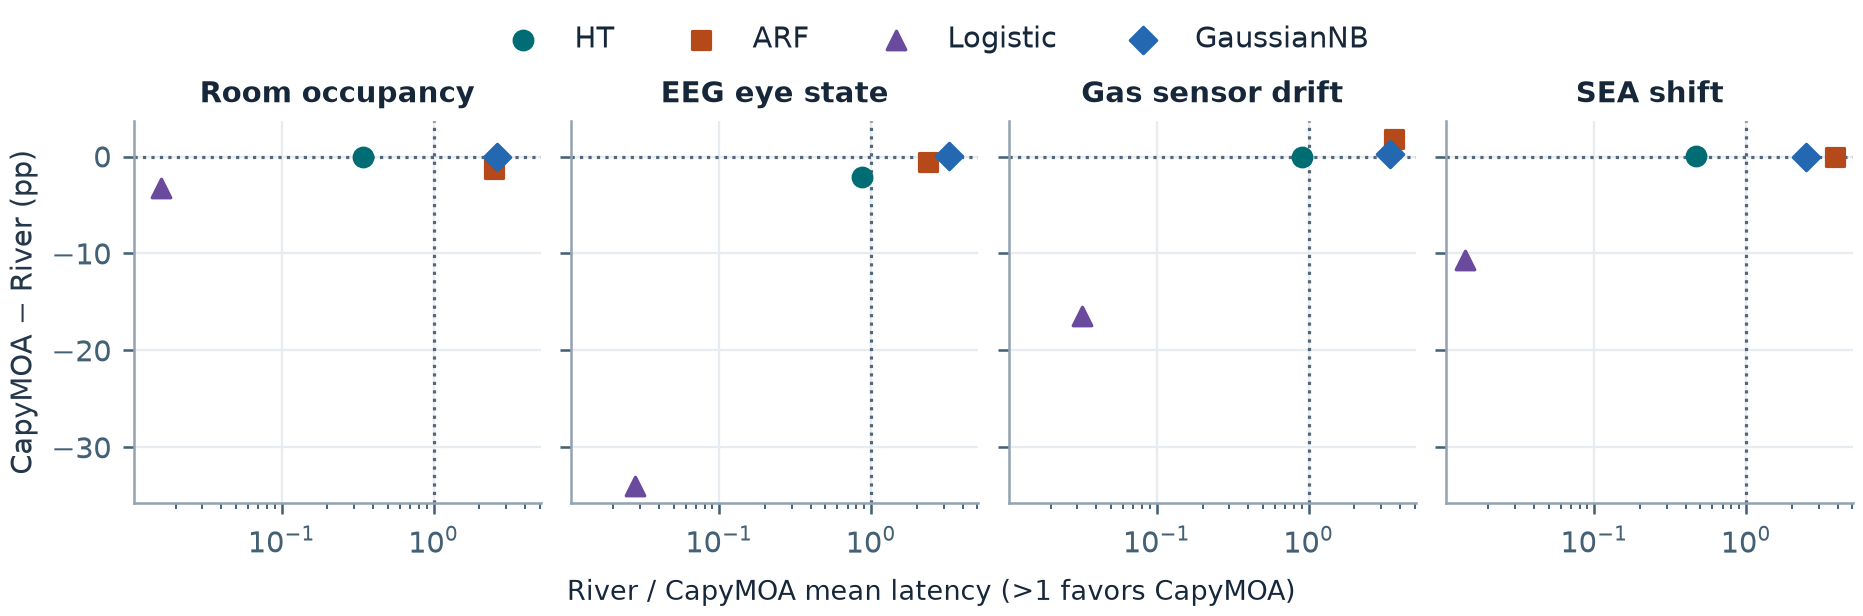

In [7]:
cost_keys = ['stream', 'model', 'accuracy', 'wall_s', 'mean_us', 'p95_us', 'rss_peak_mib']
capy = read('capymoa_classification')
paired = clf[cost_keys].merge(capy[cost_keys], on=['stream', 'model'], suffixes=('_river', '_capymoa'))
display(paired)
plot('cross_library')

## CapyMOA clustering

Score every new block with the previous snapshot’s centers. Compute adjusted Rand index against held-back occupancy labels or simulated group IDs. ClusTree exposes micro-centers.

,stream,model,n,mean_ari,scored_blocks,first_post_shift_ari,last_4_blocks_ari,final_centers,wall_s,mean_train_us,p95_train_us,mean_snapshot_ms
0,OccupancySensors,CluStream,6000,0.8072,23,NaN,0.8189,2,0.2516,34.8153,31.5861,1.1712
1,OccupancySensors,DenStream,6000,0.7916,22,NaN,0.8306,2,0.9763,99.9341,132.7941,15.1345
2,OccupancySensors,ClusTree,6000,0.4176,23,NaN,0.3358,14,0.0497,5.5662,7.1250,0.2470
3,GaussianShift,CluStream,6000,0.8312,23,0.8987,0.7301,3,0.1890,27.9800,30.7080,0.3985
4,GaussianShift,DenStream,6000,0.7291,22,0.5852,1.0000,3,0.4639,50.3538,69.4632,5.3646
5,GaussianShift,ClusTree,6000,0.3275,23,0.7811,0.4423,15,0.0683,5.1860,6.0000,0.7277


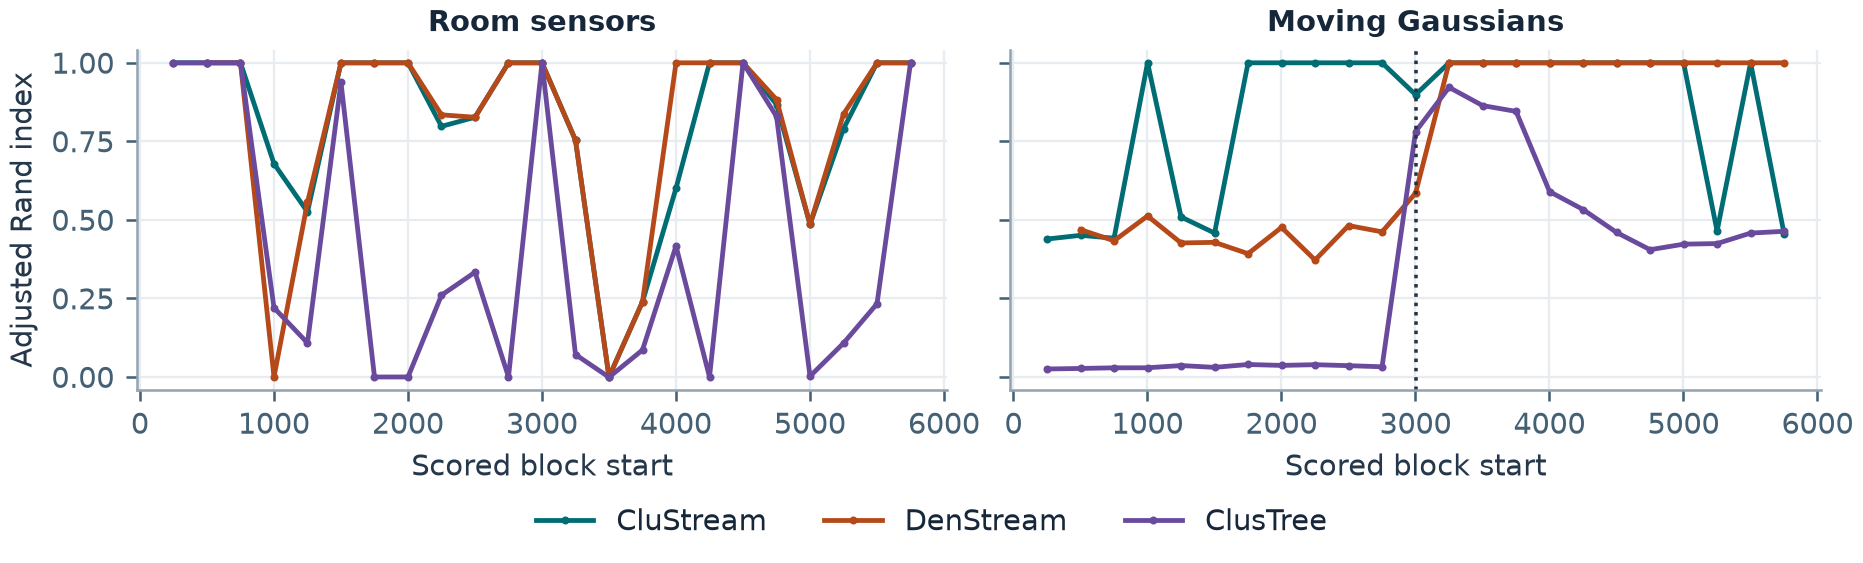

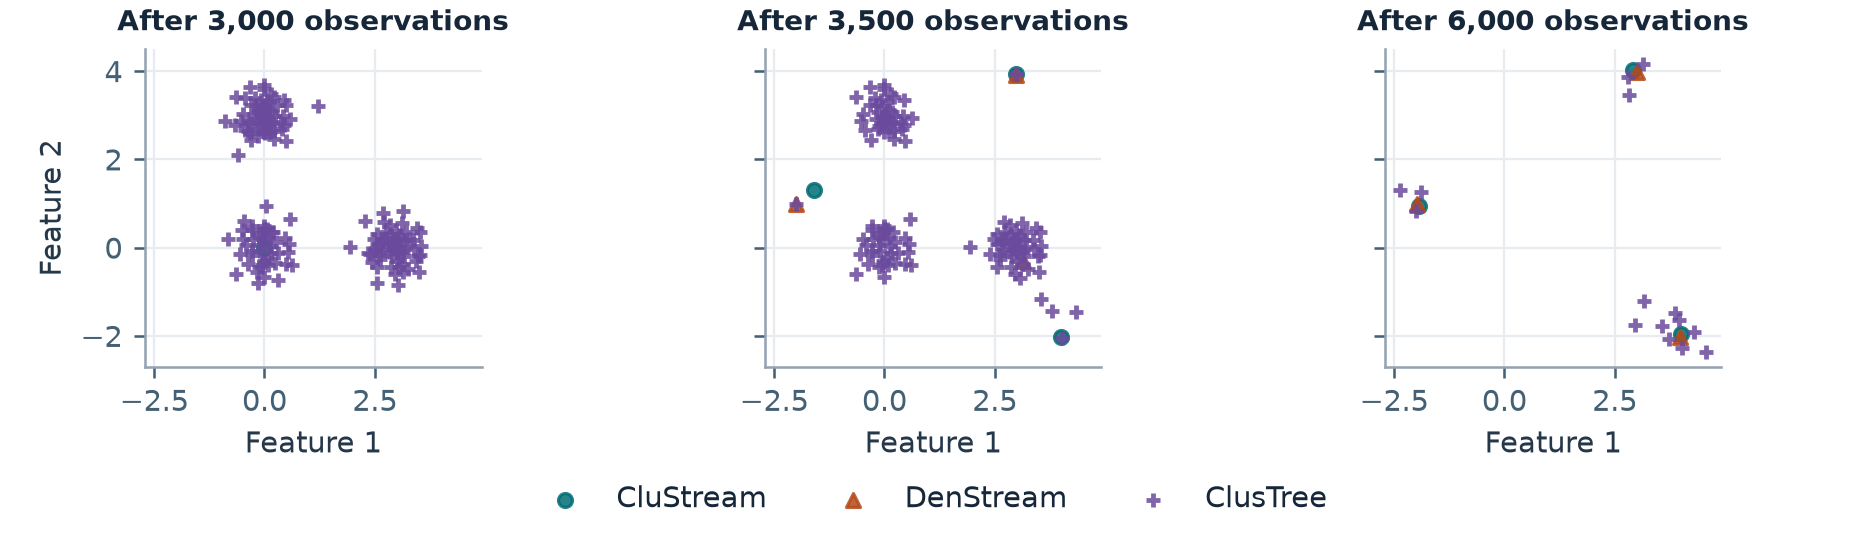

In [8]:
display(read('clustering'))
plot('clustering')
plot('cluster_centers')

## Bonus · Online model selection

Three CapyMOA selectors compete against fixed Hoeffding and Hoeffding Adaptive Trees on SEA. Post-change accuracy covers the first 1,000 observations after the switch.

,model,accuracy,macro_f1,kappa,first_1000_after,wall_s,mean_us,p95_us
0,HT (g=100),0.8225,0.8222,0.6491,0.5580,0.2101,20.6664,21.5830
1,HAT (g=100),0.8934,0.8931,0.7862,0.7600,0.2325,22.8869,25.1292
2,Bandit,0.8132,0.8128,0.6308,0.5650,30.9696,"3,096.3556","3,223.0565"
3,Successive halving,0.8924,0.8921,0.7842,0.7600,33.8251,"3,381.9328","11,510.8402"
4,AutoClass,0.9022,0.9019,0.8038,0.7790,0.8039,79.9518,54.2982


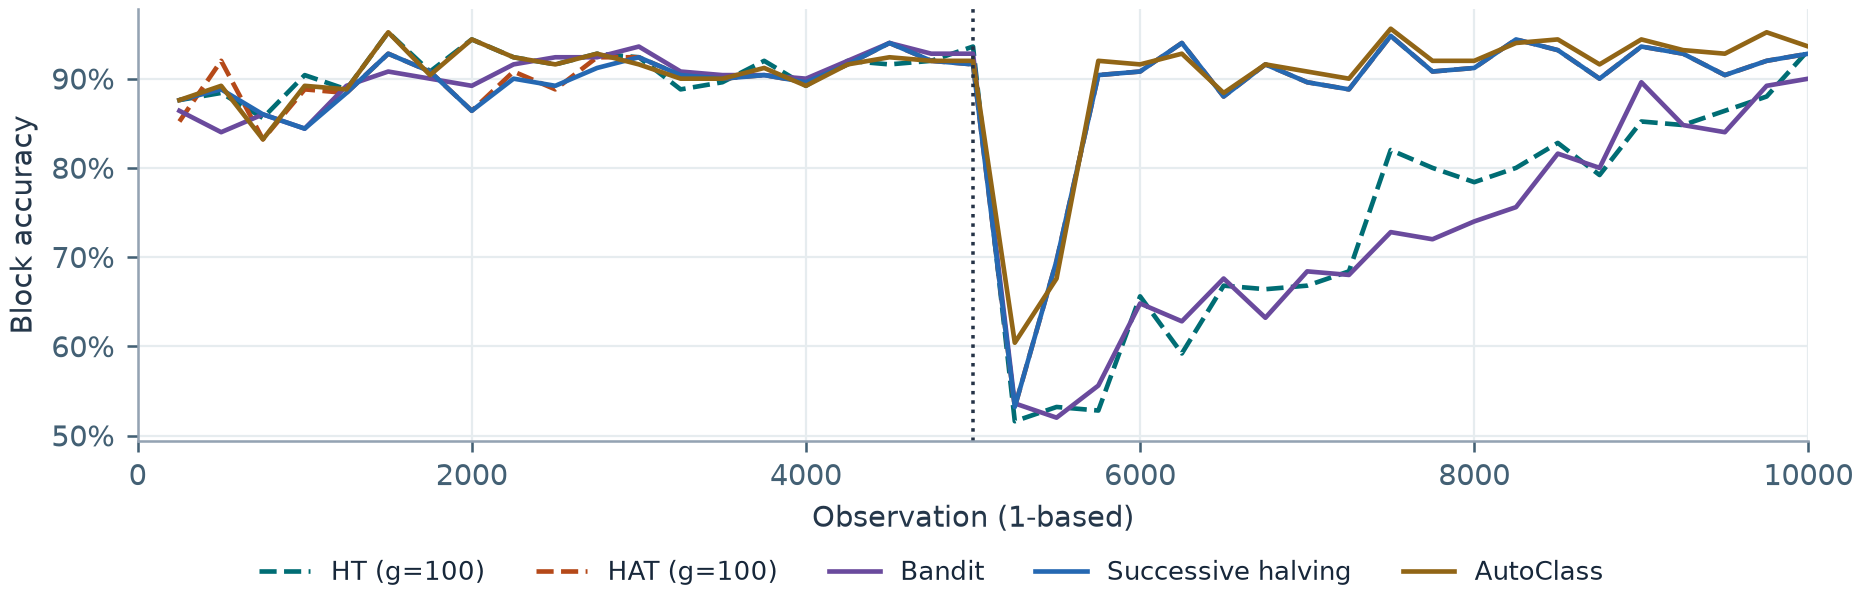

In [9]:
display(read('automl')[['model', 'accuracy', 'macro_f1', 'kappa', 'first_1000_after', 'wall_s', 'mean_us', 'p95_us']])
plot('automl')